# 03 — Hypothesis: ordinary scaling

### How to read this notebook
Run cells top to bottom. Each Markdown cell states the question and expected result **before** the code. The printed and plotted numbers are measurements, not claims made in advance. The shared functions live in `src/experiment.py`. Open Jupyter from the project root so imports work.

## What changes?

For each $\alpha$, use the **same numerical initialization** and the same unscaled underlying examples. Only the two complex input coordinates are multiplied by $\alpha$. This changes initial preactivations, ReLU gates, predictions, and potentially gradients. Thus it measures the **total** scaling effect, not a unique mechanism.

We measure full-data accuracy **and** conflict-set reliance. On conflicting inputs the simple and complex signals disagree; these examples are out of the training distribution. Complex reliance is the fraction of conflict examples classified according to the complex signal.

In [1]:
from src.experiment import *
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
print('PyTorch:', torch.__version__)

PyTorch: 2.14.1+cpu


0.1 {'step': 500, 'loss': 0.019071761518716812, 'accuracy': 1.0, 'complex_reliance': 0.0, 'simple_flip_rate': 1.0, 'complex_flip_rate': 0.0, 'simple_probability_change': 0.9619623422622681, 'complex_probability_change': 0.0015381172997877002}


0.5 {'step': 500, 'loss': 0.0196538046002388, 'accuracy': 1.0, 'complex_reliance': 0.0, 'simple_flip_rate': 1.0, 'complex_flip_rate': 0.0, 'simple_probability_change': 0.9577040672302246, 'complex_probability_change': 0.008678387850522995}


1 {'step': 500, 'loss': 0.020811930298805237, 'accuracy': 1.0, 'complex_reliance': 0.0, 'simple_flip_rate': 1.0, 'complex_flip_rate': 0.0, 'simple_probability_change': 0.8917499780654907, 'complex_probability_change': 0.07035654038190842}


2 {'step': 500, 'loss': 0.01117003709077835, 'accuracy': 1.0, 'complex_reliance': 1.0, 'simple_flip_rate': 0.0, 'complex_flip_rate': 1.0, 'simple_probability_change': 0.25922730565071106, 'complex_probability_change': 0.7269519567489624}


5 {'step': 500, 'loss': 0.0027758071664720774, 'accuracy': 1.0, 'complex_reliance': 1.0, 'simple_flip_rate': 0.0, 'complex_flip_rate': 1.0, 'simple_probability_change': 0.011493059806525707, 'complex_probability_change': 0.9834577441215515}


10 {'step': 500, 'loss': 0.0008737469324842095, 'accuracy': 1.0, 'complex_reliance': 1.0, 'simple_flip_rate': 0.0, 'complex_flip_rate': 1.0, 'simple_probability_change': 0.0016347636701539159, 'complex_probability_change': 0.9966930150985718}


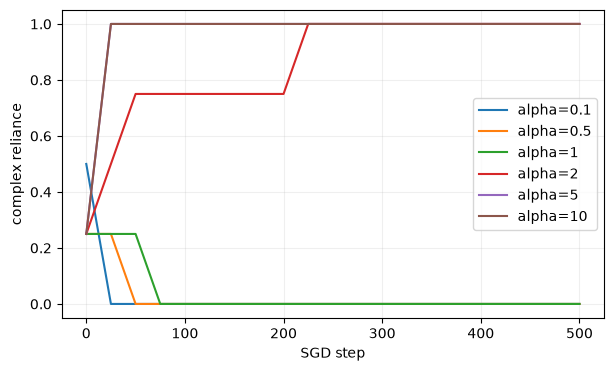

In [2]:
alphas=[0.1,0.5,1,2,5,10]
all_runs={}
summary=[]
for alpha in alphas:
    x,y=make_data(1024,seed=11,alpha=alpha)
    m=make_model(seed=42)
    history=train(m,x,y,steps=500,lr=0.03,alpha=alpha)
    all_runs[f'alpha={alpha}']=history
    summary.append({'experiment':'ordinary','alpha':alpha,**history[-1]})
    print(alpha,history[-1])
plot_histories(all_runs)
save_rows(summary,'results/03_ordinary.csv')

## What to conclude

A change in conflict reliance is evidence of a changed learned behavior under this diagnostic, not evidence by itself that gradient scaling was the cause. The next notebook removes differences in the **initial function**.